In [1]:
import lightgbm as lgb
from lightgbm import LGBMRegressor

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [2]:
data = pd.read_csv("aqi_with_lag_features.csv")
HORIZON = 24

data["target_pm25_24h"] = (
    data["pm2_5_ugm3"].shift(-HORIZON)
)

In [3]:
print(
    data[
        ["pm2_5_ugm3", "target_pm25_24h"]
    ].tail(30)
)

       pm2_5_ugm3  target_pm25_24h
28818        82.2             88.5
28819        83.1             86.8
28820        83.8             83.6
28821        85.0             81.5
28822        86.4             81.3
28823        87.1             83.6
28824        86.4              NaN
28825        84.5              NaN
28826        82.4              NaN
28827        79.4              NaN
28828        76.4              NaN
28829        77.5              NaN
28830        75.7              NaN
28831        75.7              NaN
28832        75.0              NaN
28833        72.9              NaN
28834        71.7              NaN
28835        71.7              NaN
28836        77.3              NaN
28837        79.2              NaN
28838        78.2              NaN
28839        76.8              NaN
28840        76.4              NaN
28841        90.1              NaN
28842        88.5              NaN
28843        86.8              NaN
28844        83.6              NaN
28845        81.5   

In [4]:
data.columns.to_list()

['datetime',
 'year',
 'month',
 'hour',
 'day_of_week',
 'temp_2m_c',
 'humidity_percent',
 'wind_speed_10m_kmh',
 'wind_dir_10m',
 'wind_gusts_kmh',
 'wind_stagnation',
 'precipitation_mm',
 'pressure_msl_hpa',
 'solar_radiation_wm2',
 'cloud_cover_percent',
 'pm2_5_ugm3',
 'pm10_ugm3',
 'co_ugm3',
 'no2_ugm3',
 'so2_ugm3',
 'o3_ugm3',
 'dust_ugm3',
 'aod',
 'festival_period',
 'crop_burning_season',
 'pm2_5_ugm3_lag1',
 'pm2_5_ugm3_lag2',
 'pm2_5_ugm3_lag3',
 'pm2_5_ugm3_lag6',
 'pm2_5_ugm3_lag12',
 'pm2_5_ugm3_lag24',
 'pm2_5_ugm3_lag48',
 'pm2_5_ugm3_lag72',
 'pm2_5_ugm3_lag168',
 'pm10_ugm3_lag1',
 'pm10_ugm3_lag2',
 'pm10_ugm3_lag3',
 'pm10_ugm3_lag6',
 'pm10_ugm3_lag12',
 'pm10_ugm3_lag24',
 'pm10_ugm3_lag48',
 'pm10_ugm3_lag72',
 'pm10_ugm3_lag168',
 'no2_ugm3_lag3',
 'no2_ugm3_lag24',
 'co_ugm3_lag3',
 'co_ugm3_lag24',
 'so2_ugm3_lag3',
 'so2_ugm3_lag24',
 'o3_ugm3_lag3',
 'o3_ugm3_lag24',
 'pm_roll6_mean',
 'pm_roll24_mean',
 'pm_roll72_mean',
 'pm_roll168_mean',
 'pm_roll24

In [5]:
data[
    [
        "datetime",
        "pm2_5_ugm3",
        "target_pm25_next24h",
        "target_pm25_24h"
    ]
].head(30)

difference = (
    data["target_pm25_next24h"]
    - data["target_pm25_24h"]
).abs()

print("Maximum difference:", difference.max())
print("Number of different rows:", (difference > 0).sum())

Maximum difference: 0.0
Number of different rows: 0


In [6]:
target_column = "target_pm25_24h"
data["datetime"] = pd.to_datetime(data["datetime"])

data = (
    data
    .sort_values("datetime")
    .reset_index(drop=True)
)
print(
    "Duplicate timestamps:",
    data["datetime"].duplicated().sum()
)
print(
    data["datetime"]
    .diff()
    .value_counts()
    .head()
)

Duplicate timestamps: 0
datetime
0 days 01:00:00    28847
Name: count, dtype: int64


In [7]:
pm25_features = [
    "pm2_5_ugm3",
    "pm2_5_ugm3_lag1",
    "pm2_5_ugm3_lag2",
    "pm2_5_ugm3_lag3",
    "pm2_5_ugm3_lag6",
    "pm2_5_ugm3_lag12",
    "pm2_5_ugm3_lag24",
    "pm2_5_ugm3_lag48",
    "pm2_5_ugm3_lag72",
    "pm2_5_ugm3_lag168"
]
pm10_features = [
    "pm10_ugm3",
    "pm10_ugm3_lag1",
    "pm10_ugm3_lag2",
    "pm10_ugm3_lag3",
    "pm10_ugm3_lag6",
    "pm10_ugm3_lag12",
    "pm10_ugm3_lag24",
    "pm10_ugm3_lag48",
    "pm10_ugm3_lag72",
    "pm10_ugm3_lag168"
]
pollutant_features = [
    "co_ugm3",
    "no2_ugm3",
    "so2_ugm3",
    "o3_ugm3",
    "dust_ugm3",
    "aod",

    "no2_ugm3_lag3",
    "no2_ugm3_lag24",
    "co_ugm3_lag3",
    "co_ugm3_lag24",
    "so2_ugm3_lag3",
    "so2_ugm3_lag24",
    "o3_ugm3_lag3",
    "o3_ugm3_lag24"
]
history_summary_features = [
    "pm_roll6_mean",
    "pm_roll24_mean",
    "pm_roll72_mean",
    "pm_roll168_mean",
    "pm_roll24_max",
    "pm_roll72_max",
    "pm_roll24_std",
    "pm_trend_24"
]
weather_features = [
    "temp_2m_c",
    "humidity_percent",
    "wind_speed_10m_kmh",
    "wind_gusts_kmh",
    "wind_stagnation",
    "precipitation_mm",
    "pressure_msl_hpa",
    "solar_radiation_wm2",
    "cloud_cover_percent",
    "rain_6h",
    "rain_24h",
    "wind_roll24_mean",
    "stagnation_24h",
    "wind_u",
    "wind_v"
]

In [8]:
HORIZON = 24

target_datetime = (
    data["datetime"]
    + pd.Timedelta(hours=HORIZON)
)

data["target_hour"] = target_datetime.dt.hour
data["target_day_of_week"] = target_datetime.dt.dayofweek
data["target_month"] = target_datetime.dt.month

data["target_hour_sin"] = np.sin(
    2 * np.pi * data["target_hour"] / 24
)

data["target_hour_cos"] = np.cos(
    2 * np.pi * data["target_hour"] / 24
)

data["target_day_sin"] = np.sin(
    2 * np.pi * data["target_day_of_week"] / 7
)

data["target_day_cos"] = np.cos(
    2 * np.pi * data["target_day_of_week"] / 7
)

data["target_month_sin"] = np.sin(
    2 * np.pi * (data["target_month"] - 1) / 12
)

data["target_month_cos"] = np.cos(
    2 * np.pi * (data["target_month"] - 1) / 12
)

In [9]:
calendar_features = [
    "target_hour_sin",
    "target_hour_cos",
    "target_day_sin",
    "target_day_cos",
    "target_month_sin",
    "target_month_cos",
    "festival_period",
    "crop_burning_season"
]
model_features = (
    pm25_features
    + pm10_features
    + pollutant_features
    + history_summary_features
    + weather_features
    + calendar_features
)

target_column = "target_pm25_24h"

print("Number of model features:", len(model_features))

missing_features = [
    feature
    for feature in model_features
    if feature not in data.columns
]

print("Missing features:", missing_features)

non_numeric_features = (
    data[model_features]
    .select_dtypes(exclude=np.number)
    .columns
    .tolist()
)

print("Non-numeric features:", non_numeric_features)

Number of model features: 65
Missing features: []
Non-numeric features: []


In [10]:
required_columns = (
    model_features
    + [target_column]
)

model_data = (
    data[
        ["datetime"] + required_columns
    ]
    .dropna()
    .copy()
)

X = model_data[model_features]
y = model_data[target_column]
timestamps = model_data["datetime"]

print("Original rows:", len(data))
print("Usable rows:", len(model_data))
print("X shape:", X.shape)
print("y shape:", y.shape)

data["pm_roll24_mean"] = (
    data["pm2_5_ugm3"]
    .rolling(24)
    .mean()
)

Original rows: 28848
Usable rows: 28824
X shape: (28824, 65)
y shape: (28824,)


In [11]:
total_rows = len(model_data)

train_end = int(total_rows * 0.70)
validation_end = int(total_rows * 0.85)

X_train = X.iloc[:train_end]
y_train = y.iloc[:train_end]

X_validation = X.iloc[train_end:validation_end]
y_validation = y.iloc[train_end:validation_end]

X_test = X.iloc[validation_end:]
y_test = y.iloc[validation_end:]

train_times = timestamps.iloc[:train_end]
validation_times = timestamps.iloc[
    train_end:validation_end
]
test_times = timestamps.iloc[validation_end:]

In [12]:
print(
    "Training:",
    train_times.min(),
    "to",
    train_times.max()
)

print(
    "Validation:",
    validation_times.min(),
    "to",
    validation_times.max()
)

print(
    "Testing:",
    test_times.min(),
    "to",
    test_times.max()
)

Training: 2022-08-12 00:00:00 to 2024-11-29 15:00:00
Validation: 2024-11-29 16:00:00 to 2025-05-28 19:00:00
Testing: 2025-05-28 20:00:00 to 2025-11-24 23:00:00


In [13]:
import lightgbm as lgb
from lightgbm import LGBMRegressor

In [14]:
lightgbm_model = LGBMRegressor(
    objective="regression_l1",

    n_estimators=3000,
    learning_rate=0.03,

    num_leaves=31,
    max_depth=10,
    min_child_samples=50,

    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,

    reg_alpha=0.1,
    reg_lambda=1.0,

    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

In [15]:
lightgbm_model.fit(
    X_train,
    y_train,

    eval_set=[
        (X_validation, y_validation)
    ],

    eval_metric="mae",

    callbacks=[
        lgb.early_stopping(
            stopping_rounds=100
        ),
        lgb.log_evaluation(
            period=100
        )
    ]
)

C:\Users\Vishal Panindre\AppData\Local\Programs\Python\Python311\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 100 rounds
[100]	valid_0's l1: 10.7155
[200]	valid_0's l1: 10.6757
Early stopping, best iteration is:
[163]	valid_0's l1: 10.6574


LGBMRegressor(colsample_bytree=0.8, learning_rate=0.03, max_depth=10,
              min_child_samples=50, n_estimators=3000, n_jobs=-1,
              objective='regression_l1', random_state=42, reg_alpha=0.1,
              reg_lambda=1.0, subsample=0.8, subsample_freq=1, verbosity=-1)

In [16]:
print(
    "Best iteration:",
    lightgbm_model.best_iteration_
)

Best iteration: 163


In [17]:
validation_predictions = lightgbm_model.predict(
    X_validation,
    num_iteration=lightgbm_model.best_iteration_
)

In [18]:
prediction_results = pd.DataFrame({
    "datetime": validation_times.values,
    "actual_pm25_24h": y_validation.values,
    "predicted_pm25_24h": validation_predictions
})

print(prediction_results.head(10))

             datetime  actual_pm25_24h  predicted_pm25_24h
0 2024-11-29 16:00:00             55.5           44.802297
1 2024-11-29 17:00:00             66.8           47.214996
2 2024-11-29 18:00:00             65.9           47.073796
3 2024-11-29 19:00:00             66.8           45.678918
4 2024-11-29 20:00:00             68.9           46.807307
5 2024-11-29 21:00:00             70.3           45.151420
6 2024-11-29 22:00:00             70.3           42.981938
7 2024-11-29 23:00:00             69.2           43.228710
8 2024-11-30 00:00:00             67.8           43.789056
9 2024-11-30 01:00:00             67.5           44.803558


In [19]:
lgbm_mae = mean_absolute_error(
    y_validation,
    validation_predictions
)

lgbm_rmse = np.sqrt(
    mean_squared_error(
        y_validation,
        validation_predictions
    )
)

lgbm_r2 = r2_score(
    y_validation,
    validation_predictions
)

print("LightGBM validation results")
print("MAE:", round(lgbm_mae, 3))
print("RMSE:", round(lgbm_rmse, 3))
print("R²:", round(lgbm_r2, 3))

LightGBM validation results
MAE: 10.657
RMSE: 15.562
R²: 0.565


In [20]:
prediction_errors = (
    validation_predictions
    - y_validation.values
)

print(
    "Average actual PM2.5:",
    round(y_validation.mean(), 3)
)

print(
    "Average predicted PM2.5:",
    round(validation_predictions.mean(), 3)
)

print(
    "Average error:",
    round(prediction_errors.mean(), 3)
)

Average actual PM2.5: 45.597
Average predicted PM2.5: 42.499
Average error: -3.099


In [21]:
train_predictions = lightgbm_model.predict(
    X_train,
    num_iteration=lightgbm_model.best_iteration_
)

train_mae = mean_absolute_error(
    y_train,
    train_predictions
)

train_rmse = np.sqrt(
    mean_squared_error(
        y_train,
        train_predictions
    )
)

train_r2 = r2_score(
    y_train,
    train_predictions
)

print("Training results")
print("MAE:", round(train_mae, 3))
print("RMSE:", round(train_rmse, 3))
print("R²:", round(train_r2, 3))

print("\nValidation results")
print("MAE:", round(lgbm_mae, 3))
print("RMSE:", round(lgbm_rmse, 3))
print("R²:", round(lgbm_r2, 3))

Training results
MAE: 8.171
RMSE: 18.441
R²: 0.761

Validation results
MAE: 10.657
RMSE: 15.562
R²: 0.565


In [22]:
baseline_predictions = (
    X_validation["pm2_5_ugm3"].values
)

baseline_mae = mean_absolute_error(
    y_validation,
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_validation,
        baseline_predictions
    )
)

baseline_r2 = r2_score(
    y_validation,
    baseline_predictions
)

comparison = pd.DataFrame({
    "Model": [
        "24-hour baseline",
        "LightGBM"
    ],
    "MAE": [
        baseline_mae,
        lgbm_mae
    ],
    "RMSE": [
        baseline_rmse,
        lgbm_rmse
    ],
    "R2": [
        baseline_r2,
        lgbm_r2
    ]
})

print(comparison.round(3))

              Model     MAE    RMSE     R2
0  24-hour baseline  11.396  16.565  0.507
1          LightGBM  10.657  15.562  0.565


In [23]:
feature_importance = pd.DataFrame({
    "feature": model_features,
    "importance": (
        lightgbm_model.booster_
        .feature_importance(
            importance_type="gain"
        )
    )
})

feature_importance = (
    feature_importance
    .sort_values(
        "importance",
        ascending=False
    )
    .reset_index(drop=True)
)

feature_importance["importance_percent"] = (
    feature_importance["importance"]
    / feature_importance["importance"].sum()
    * 100
)

print(
    feature_importance[
        ["feature", "importance_percent"]
    ].head(20)
)

              feature  importance_percent
0          pm2_5_ugm3           51.417428
1     pm2_5_ugm3_lag1            9.637429
2     pm_roll168_mean            4.235359
3    target_month_cos            3.591320
4       pm_roll6_mean            3.089268
5       pm_roll72_max            1.395206
6    target_month_sin            1.292549
7    wind_roll24_mean            1.250996
8      pm_roll72_mean            1.184536
9            rain_24h            1.177623
10  pm2_5_ugm3_lag168            1.176267
11   pressure_msl_hpa            1.170594
12       co_ugm3_lag3            1.040571
13          dust_ugm3            0.991633
14      pm_roll24_max            0.952475
15            o3_ugm3            0.801713
16            co_ugm3            0.790869
17   pm10_ugm3_lag168            0.764935
18   pm2_5_ugm3_lag72            0.727688
19    pm10_ugm3_lag72            0.706755


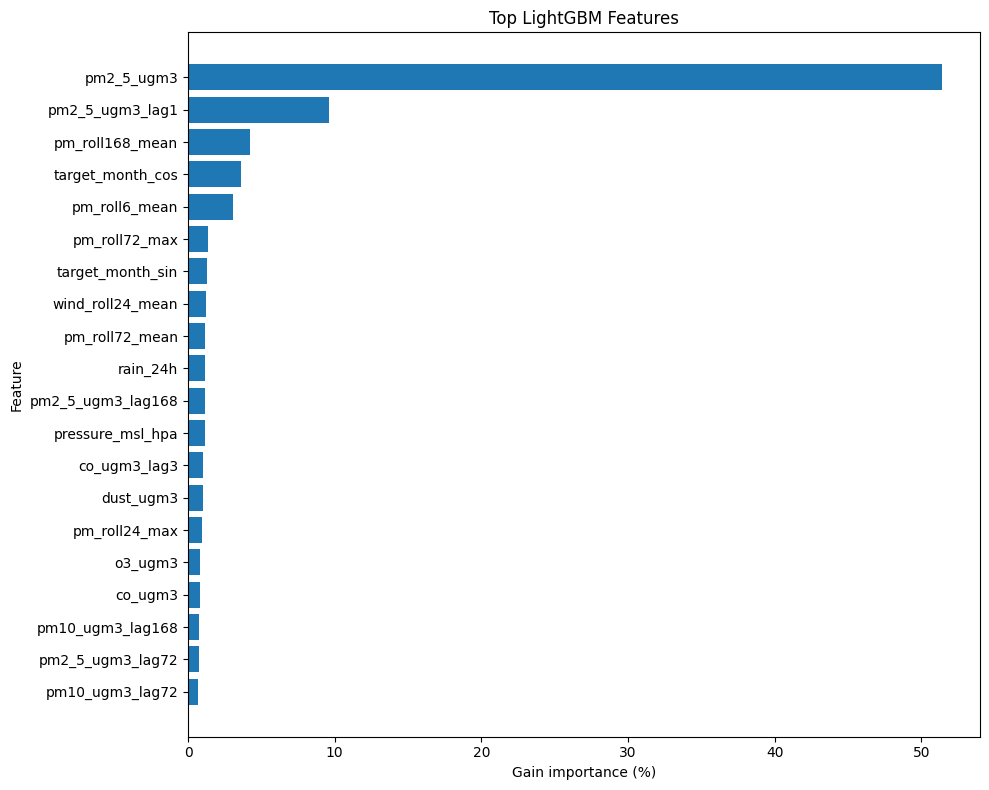

In [24]:
top_features = (
    feature_importance
    .head(20)
    .sort_values("importance_percent")
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["feature"],
    top_features["importance_percent"]
)

plt.title("Top LightGBM Features")
plt.xlabel("Gain importance (%)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

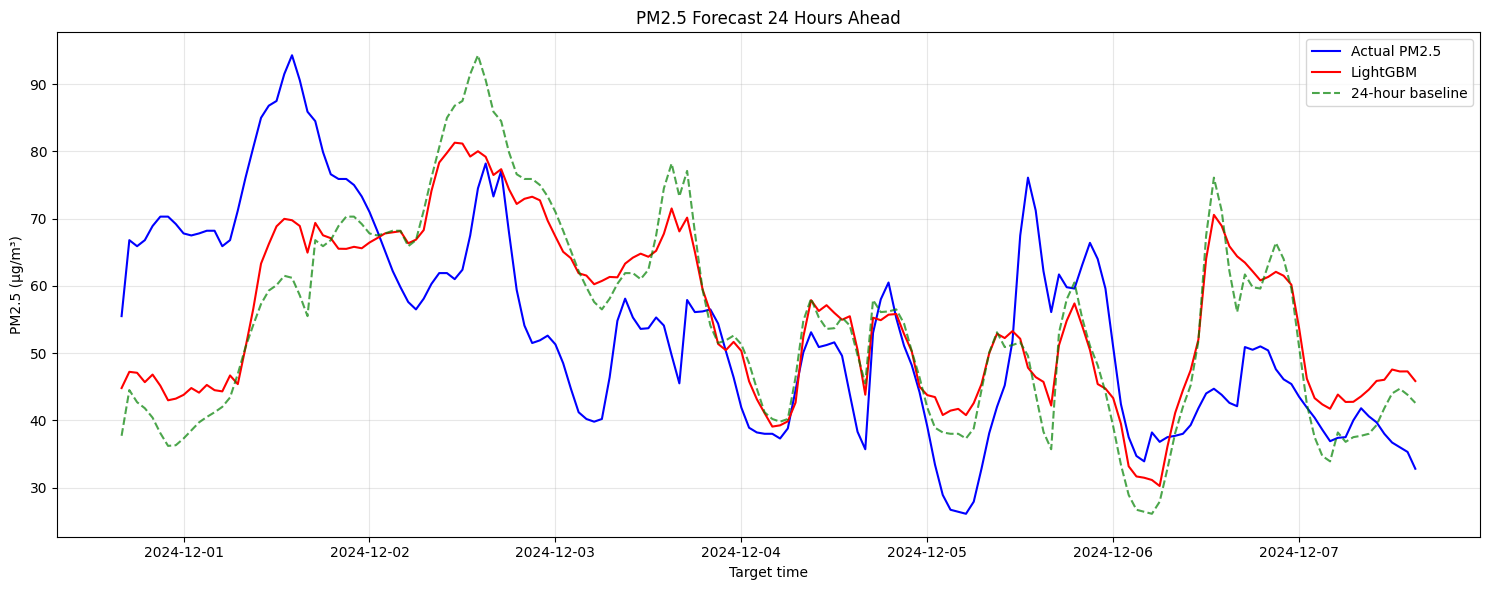

In [25]:
target_times = (
    validation_times
    + pd.Timedelta(hours=24)
)

hours_to_display = 24 * 7

plt.figure(figsize=(15, 6))

plt.plot(
    target_times.iloc[:hours_to_display],
    y_validation.iloc[:hours_to_display],
    label="Actual PM2.5",
    color="blue"
)

plt.plot(
    target_times.iloc[:hours_to_display],
    validation_predictions[:hours_to_display],
    label="LightGBM",
    color="red"
)

plt.plot(
    target_times.iloc[:hours_to_display],
    baseline_predictions[:hours_to_display],
    label="24-hour baseline",
    color="green",
    linestyle="--",
    alpha=0.7
)

plt.title("PM2.5 Forecast 24 Hours Ahead")
plt.xlabel("Target time")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()